In [13]:
import matplotlib.pyplot as plt
import numpy as np

In [14]:
nbc_gs = np.array([-3.968253968253968e-04, 2.133730158730159e+00,
-5.510166666666667e+02, 3.350016111111111e+04,
-8.126651111111111e+05, 1.007618376666667e+07,
-7.324138297777778e+07, 3.390596320730159e+08,
-1.052539536278571e+09, 2.259013328583333e+09,
-3.399701984433333e+09, 3.582450461700000e+09,
-2.591494081366667e+09, 1.227049828766667e+09,
-3.427345554285714e+08, 4.284181942857143e+07])

In [15]:
from functools import cache
#from math import factorial
def factorial(s):
    x = s*1
    y = 1
    while x>0:
        y *= x
        x -= 1
    return y

def gaver_stehfest_coefficients(N):
    """ Inverse laplace transform using Gaver-Stehfest method.
        see https://dl.acm.org/doi/10.1145/361953.361969
        Algorithm 368: Numerical inversion of laplace transforms
    """
    idx = np.arange(N)+1
    k_lower = (idx+1)//2
    k_upper = np.clip(idx, 0, N/2)+1
    v = np.zeros(N)

    for i in idx:
        tmpv = 0
        for k in np.arange(k_lower[i-1], k_upper[i-1]):
            numerator = factorial(2*k)
            numerator *= k**(N/2)# niels code values when next line is commented
            denominator = factorial(N/2 - k)
            denominator *= factorial(k)
            denominator *= factorial(k-1)
            denominator *= factorial(i-k)
            denominator *= factorial(2*k-i)
            tmpv += numerator/denominator
        v[i-1] = (-1)**(i + N/2)*tmpv

    return v

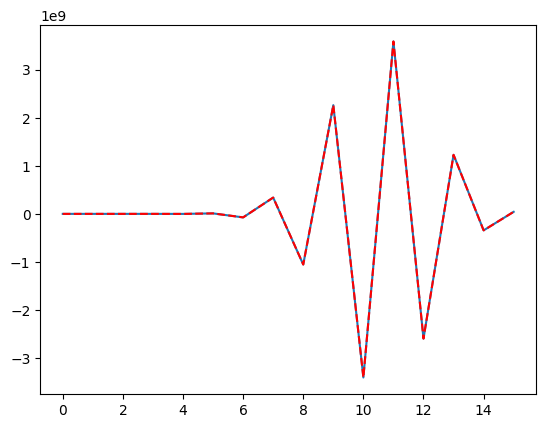

In [16]:
#from math import factorial

N = 16
v = gaver_stehfest_coefficients(N)

# idx = np.arange(N)+1
# k_lower = (idx+1)//2
# k_upper = np.clip(idx, 0, N/2)+1
# v = np.zeros(N)
# # def factorial(s):
# #     x = s*1
# #     y = 1
# #     while x>0:
# #         y *= x
# #         x -= 1
# #     return y



# for i in idx:
#     tmpv = 0
#     for k in np.arange(k_lower[i-1], k_upper[i-1]):
#         numerator = factorial(2*k)
#         numerator *= k**(N/2)# niels code values when next line is commented
#         denominator = factorial(N/2 - k)
#         denominator *= factorial(k)
#         denominator *= factorial(k-1)
#         denominator *= factorial(i-k)
#         denominator *= factorial(2*k-i)
#         tmpv += numerator/denominator
#     v[i-1] = (-1)**(i + N/2)*tmpv


fig,axs = plt.subplots()
axs = [axs]
axs[0].plot(nbc_gs)
axs[0].plot(v, 'r--')
# axs[1].plot(nbc_gs)
# axs[1].plot(v, 'r')
# axs[2].plot(nbc_gs)
# axs[2].plot(v, 'r')
# for ax in axs:
#     ax.set_yscale('log')

In [7]:
v = gaver_stehfest_coefficients(16)